In [204]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 

In [205]:
df = pd.read_csv("spam.csv", encoding="latin-1")

In [206]:
df.head()

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


In [207]:
df.shape

(5572, 5)

## Data cleaning

In [208]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   v1          5572 non-null   str  
 1   v2          5572 non-null   str  
 2   Unnamed: 2  50 non-null     str  
 3   Unnamed: 3  12 non-null     str  
 4   Unnamed: 4  6 non-null      str  
dtypes: str(5)
memory usage: 677.1 KB


In [209]:
# drop last three columns larg amount of data is missing 
df.drop(columns=['Unnamed: 2','Unnamed: 3','Unnamed: 4'],inplace=True)

In [210]:
df.sample(3)

,v1,v2
2374,ham,Dunno lei he neva say...
3884,ham,Like a personal sized or what
3399,spam,"As a valued customer, I am pleased to advise y..."


In [211]:
# Rename the columns 
df.rename(columns={'v1':'target','v2':'text'},inplace=True)
df.sample(4)

,target,text
1809,ham,"Aight, I'll ask a few of my roommates"
3916,ham,Eh ur laptop got no stock lei... He say mon mu...
1994,ham,Have you been practising your curtsey?
2558,ham,"Some friends want me to drive em someplace, pr..."


In [212]:
from sklearn.preprocessing import LabelEncoder
encoder = LabelEncoder()
encoder

LabelEncoder()

In [213]:
df['target'] = encoder.fit_transform(df['target'])

In [214]:
df.head()

,target,text
0,0,"Go until jurong point, crazy.. Available only ..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives aro..."


In [215]:
# missing value 
df.isnull().sum()

target    0
text      0
dtype: int64

In [216]:
# check duplicate values 
df.duplicated().sum()

np.int64(403)

In [217]:
# remove duplicate 
df = df.drop_duplicates(keep='first')

In [218]:
df.duplicated().sum()

np.int64(0)

In [219]:
df.shape

(5169, 2)

# EDA

In [220]:
df['target'].value_counts()
# 0 is ham
# 1 is spam 

target
0    4516
1     653
Name: count, dtype: int64

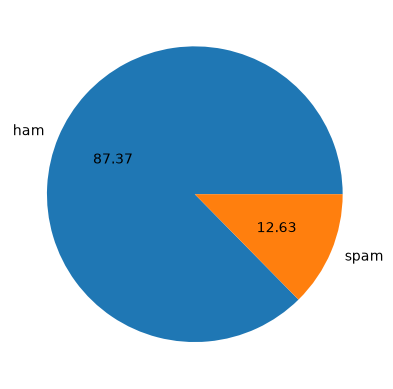

In [221]:
plt.pie(df['target'].value_counts(),labels=['ham','spam'],autopct='%0.2f')
plt.show()

In [222]:
# data is imblance 
import nltk 
# make 3 extra columns for tex_len , sent_len 

In [223]:
nltk.download("punkt_tab")

[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\Test\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [224]:
df['num_characters'] = df['text'].apply(len) # to find all row char count

In [225]:
df.head()

,target,text,num_characters
0,0,"Go until jurong point, crazy.. Available only ...",111
1,0,Ok lar... Joking wif u oni...,29
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155
3,0,U dun say so early hor... U c already then say...,49
4,0,"Nah I don't think he goes to usf, he lives aro...",61


In [226]:
# number of words 
df['num_words'] = df['text'].apply(lambda x:len(nltk.word_tokenize(x)))  # ise ye hoga ki sare text ka words count hoga ki ek santance me kitna words hai 

In [227]:
df.head()

,target,text,num_characters,num_words
0,0,"Go until jurong point, crazy.. Available only ...",111,24
1,0,Ok lar... Joking wif u oni...,29,8
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,37
3,0,U dun say so early hor... U c already then say...,49,13
4,0,"Nah I don't think he goes to usf, he lives aro...",61,15


In [228]:
# num of sentance 
df['num_sentences'] = df['text'].apply(lambda x:len(nltk.sent_tokenize(x)))

In [229]:
df.head()

,target,text,num_characters,num_words,num_sentences
0,0,"Go until jurong point, crazy.. Available only ...",111,24,2
1,0,Ok lar... Joking wif u oni...,29,8,2
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,37,2
3,0,U dun say so early hor... U c already then say...,49,13,1
4,0,"Nah I don't think he goes to usf, he lives aro...",61,15,1


In [230]:
df[['num_characters','num_words','num_sentences']].describe()

,num_characters,num_words,num_sentences
count,5169.000000,5169.000000,5169.000000
mean,78.977945,18.460437,1.965564
std,58.236293,13.334441,1.448541
min,2.000000,1.000000,1.000000
25%,36.000000,9.000000,1.000000
50%,60.000000,15.000000,1.000000
75%,117.000000,26.000000,2.000000
max,910.000000,220.000000,38.000000


In [231]:
df[df['target'] == 0][['num_characters','num_words','num_sentences']].describe()  # ham

,num_characters,num_words,num_sentences
count,4516.000000,4516.000000,4516.000000
mean,70.459256,17.128432,1.820195
std,56.358207,13.504730,1.383657
min,2.000000,1.000000,1.000000
25%,34.000000,8.000000,1.000000
50%,52.000000,13.000000,1.000000
75%,90.000000,22.000000,2.000000
max,910.000000,220.000000,38.000000


In [232]:
df[df['target'] == 1][['num_characters','num_words','num_sentences']].describe()  # spam

,num_characters,num_words,num_sentences
count,653.000000,653.000000,653.000000
mean,137.891271,27.672282,2.970904
std,30.137753,7.010932,1.488425
min,13.000000,2.000000,1.000000
25%,132.000000,25.000000,2.000000
50%,149.000000,29.000000,3.000000
75%,157.000000,32.000000,4.000000
max,224.000000,46.000000,9.000000


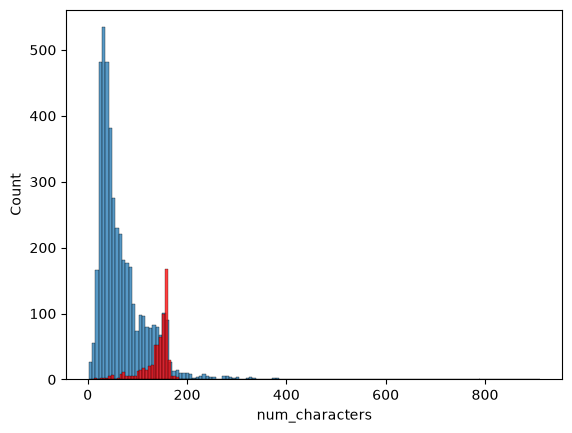

In [233]:
#plt.figure(figsize=(25,15))
sns.histplot(df[df['target']==0]['num_characters'])              # ham
sns.histplot(df[df['target']==1]['num_characters'],color='red')  # spam
plt.show()

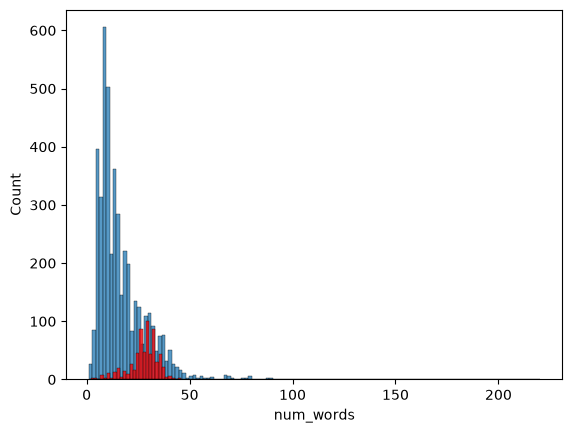

In [234]:
#plt.figure(figsize=(25,15))
sns.histplot(df[df['target']==0]['num_words'])              # ham
sns.histplot(df[df['target']==1]['num_words'],color='red')  # spam
plt.show()

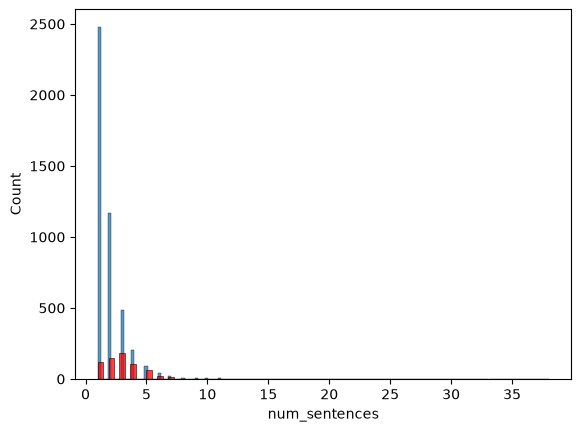

In [235]:
#plt.figure(figsize=(25,15))
sns.histplot(df[df['target']==0]['num_sentences'])              # ham
sns.histplot(df[df['target']==1]['num_sentences'],color='red')  # spam
plt.show()

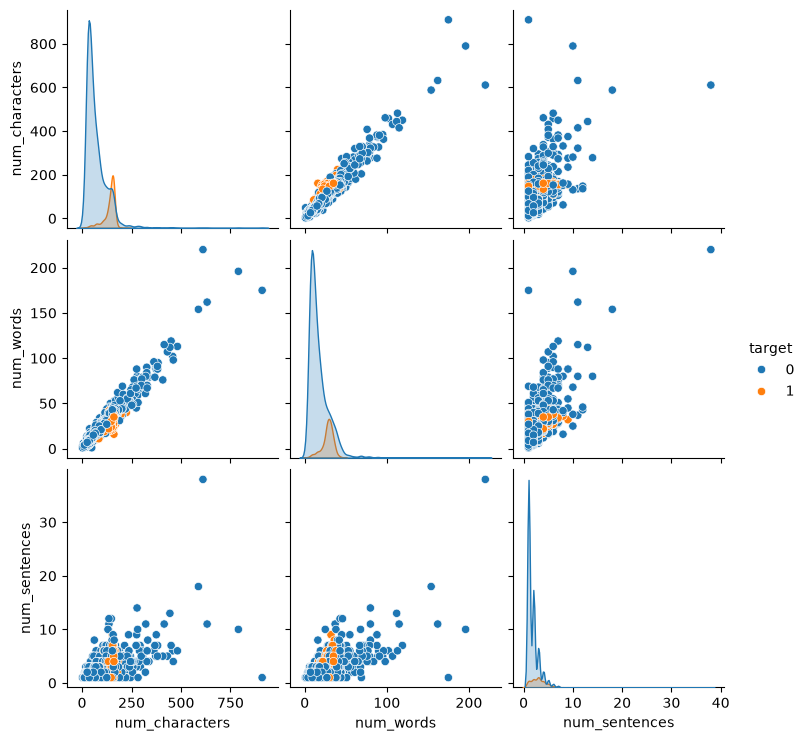

In [236]:
sns.pairplot(df, hue='target')
plt.show()

In [237]:
df.corr(numeric_only=True)

,target,num_characters,num_words,num_sentences
target,1.000000,0.384717,0.262720,0.263939
num_characters,0.384717,1.000000,0.965686,0.624139
num_words,0.262720,0.965686,1.000000,0.679767
num_sentences,0.263939,0.624139,0.679767,1.000000


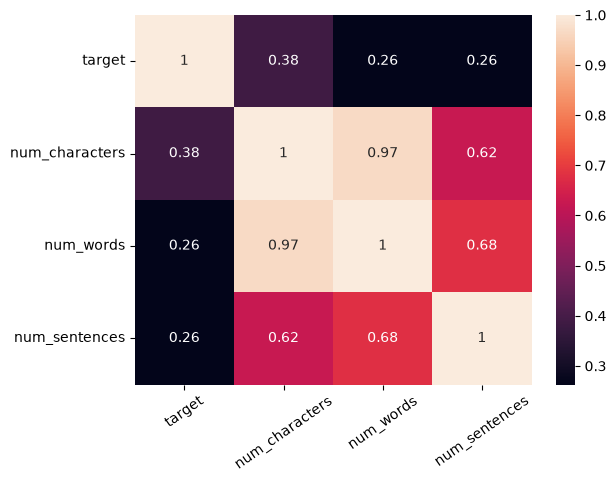

In [238]:
sns.heatmap(df.corr(numeric_only=True),annot=True)
plt.xticks(rotation=35)
plt.show()

In [239]:
import string
string.punctuation

'!"#$%&\'()*+,-./:;<=>?@[\\]^_`{|}~'

In [240]:
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Test\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [241]:
# to stop words 

from nltk.corpus import stopwords
print(stopwords.words('english'),end="")  # 198 

['a', 'about', 'above', 'after', 'again', 'against', 'ain', 'all', 'am', 'an', 'and', 'any', 'are', 'aren', "aren't", 'as', 'at', 'be', 'because', 'been', 'before', 'being', 'below', 'between', 'both', 'but', 'by', 'can', 'couldn', "couldn't", 'd', 'did', 'didn', "didn't", 'do', 'does', 'doesn', "doesn't", 'doing', 'don', "don't", 'down', 'during', 'each', 'few', 'for', 'from', 'further', 'had', 'hadn', "hadn't", 'has', 'hasn', "hasn't", 'have', 'haven', "haven't", 'having', 'he', "he'd", "he'll", 'her', 'here', 'hers', 'herself', "he's", 'him', 'himself', 'his', 'how', 'i', "i'd", 'if', "i'll", "i'm", 'in', 'into', 'is', 'isn', "isn't", 'it', "it'd", "it'll", "it's", 'its', 'itself', "i've", 'just', 'll', 'm', 'ma', 'me', 'mightn', "mightn't", 'more', 'most', 'mustn', "mustn't", 'my', 'myself', 'needn', "needn't", 'no', 'nor', 'not', 'now', 'o', 'of', 'off', 'on', 'once', 'only', 'or', 'other', 'our', 'ours', 'ourselves', 'out', 'over', 'own', 're', 's', 'same', 'shan', "shan't", 'she

In [242]:
from nltk.stem.porter import PorterStemmer
ps = PorterStemmer()
ps.stem("Dans")     # matlab ye dansing dans

'dan'

In [243]:
def transform_text(text):
    text = text.lower()
    text = nltk.word_tokenize(text)
    # text ab list me change ho gya hai to 
    y = []
    for i in text:
        if i.isalnum():
            y.append(i)
    
    text = y[:]
    y.clear()

    for i in text:
        if i not in stopwords.words('english') and i not in string.punctuation:
            y.append(i)

    text = y[:]
    y.clear()

    for i in text:
        y.append(ps.stem(i))


    return " ".join(y)

In [ ]:
# transform_text('Even my brother is not like to speak with me. They treat me like aids patent.')

'even brother like speak treat like aid patent'

In [ ]:
# df['text'][6]

'Even my brother is not like to speak with me. They treat me like aids patent.'

In [264]:
df['transform_text'] = df['text'].apply(transform_text)

In [247]:
df.head()

,target,text,num_characters,num_words,num_sentences,transform_text
0,0,"Go until jurong point, crazy.. Available only ...",111,24,2,go jurong point crazi avail bugi n great world...
1,0,Ok lar... Joking wif u oni...,29,8,2,ok lar joke wif u oni
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,37,2,free entri 2 wkli comp win fa cup final tkt 21...
3,0,U dun say so early hor... U c already then say...,49,13,1,u dun say earli hor u c alreadi say
4,0,"Nah I don't think he goes to usf, he lives aro...",61,15,1,nah think goe usf live around though


In [248]:
from wordcloud import WordCloud
wc = WordCloud(width=500,height=500,min_font_size=10,background_color='white')

In [249]:
spam_wc = wc.generate(df[df['target']==1]['transform_text'].str.cat(sep=' '))

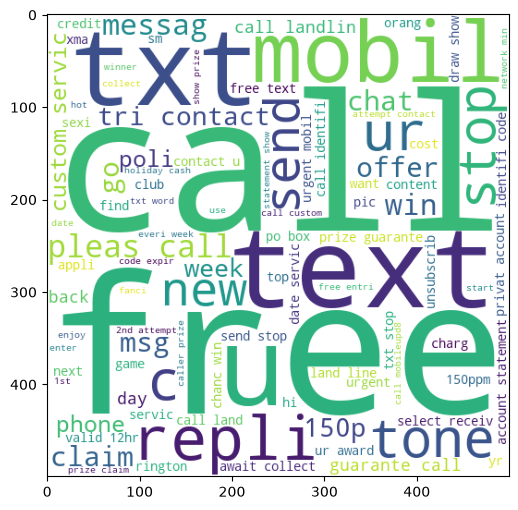

In [250]:
plt.figure(figsize=(15,6))
plt.imshow(spam_wc)
plt.show()

In [251]:
ham_wc = wc.generate(df[df['target']==0]['transform_text'].str.cat(sep=' ')) # ham ka jada tar message ayesha hi hota hai 

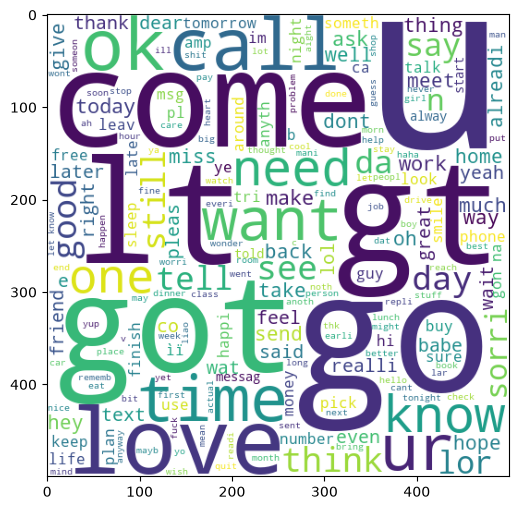

In [252]:
plt.figure(figsize=(15,6))
plt.imshow(ham_wc)
plt.show()

In [253]:
df.head(3)

,target,text,num_characters,num_words,num_sentences,transform_text
0,0,"Go until jurong point, crazy.. Available only ...",111,24,2,go jurong point crazi avail bugi n great world...
1,0,Ok lar... Joking wif u oni...,29,8,2,ok lar joke wif u oni
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,37,2,free entri 2 wkli comp win fa cup final tkt 21...


In [254]:
spam_corpus = []
for msg in df[df['target'] == 1]['transform_text'].tolist():
    for word in msg.split():
        spam_corpus.append(word)

In [255]:
len(spam_corpus)

9942

In [256]:
from collections import Counter

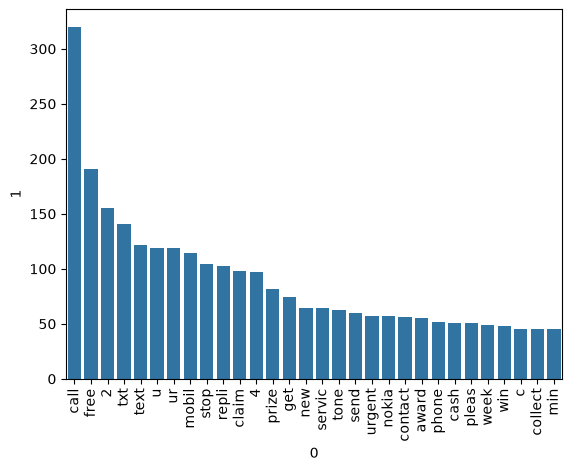

In [257]:
temp = pd.DataFrame(Counter(spam_corpus).most_common(30))

sns.barplot(x=temp[0], y=temp[1])

plt.xticks(rotation='vertical')
plt.show()

In [258]:
ham_corpus = []
for msg in df[df['target'] == 0]['transform_text'].tolist():
    for word in msg.split():
        ham_corpus.append(word)

In [259]:
print(len(ham_corpus))

35423


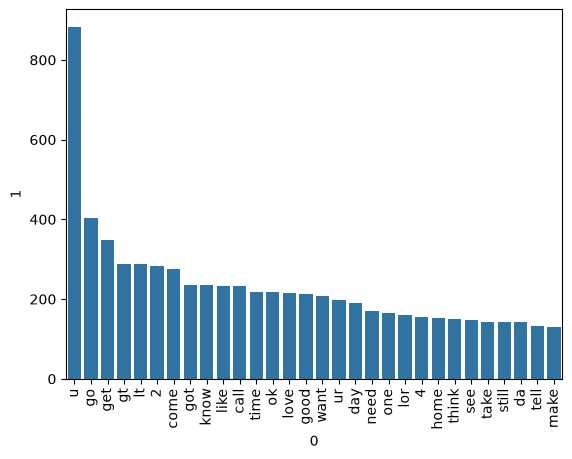

In [260]:
temp = pd.DataFrame(Counter(ham_corpus).most_common(30))

sns.barplot(x=temp[0], y=temp[1])

plt.xticks(rotation='vertical')
plt.show()

# 4 model bulding

In [284]:
from sklearn.feature_extraction.text import CountVectorizer ,TfidfVectorizer
cv = CountVectorizer()
tfidf = TfidfVectorizer()

In [285]:
X = tfidf.fit_transform(df['transform_text']).toarray()

In [286]:
X.shape

(5169, 6715)

In [287]:
y= df['target'].values

In [288]:
y

array([0, 0, 1, ..., 0, 0, 0], shape=(5169,))

In [289]:
from sklearn.model_selection import train_test_split
X_train, X_test , y_train , y_test = train_test_split(X,y,test_size=0.2,random_state=2)

In [290]:
from sklearn.naive_bayes import GaussianNB, MultinomialNB,BernoulliNB
from sklearn.metrics import accuracy_score,confusion_matrix,precision_score

In [291]:
gnb = GaussianNB()
mnb  = MultinomialNB()
bnb = BernoulliNB()

In [292]:
gnb.fit(X_train,y_train)
y_pred1 = gnb.predict(X_test)
print(accuracy_score(y_test,y_pred1))
print(confusion_matrix(y_test,y_pred1))
print(precision_score(y_test,y_pred1))

0.8762088974854932
[[793 103]
 [ 25 113]]
0.5231481481481481


In [293]:
mnb.fit(X_train,y_train)
y_pred2 = mnb.predict(X_test)
print(accuracy_score(y_test,y_pred2))
print(confusion_matrix(y_test,y_pred2))
print(precision_score(y_test,y_pred2))

0.9593810444874274
[[896   0]
 [ 42  96]]
1.0


In [279]:
bnb.fit(X_train,y_train)
y_pred3 = bnb.predict(X_test)
print(accuracy_score(y_test,y_pred3))
print(confusion_matrix(y_test,y_pred3))
print(precision_score(y_test,y_pred3))

0.9700193423597679
[[893   3]
 [ 28 110]]
0.9734513274336283


<class 'sklearn.feature_extraction.text.TfidfTransformer'>
